# Backbone sweep — predicted keypoint visualisation

For each of the **8 backbone variants** in the sweep we pick the **latest** run from
`results/sweeps/benchmark_backbone/task_{1..9}/`, load its best checkpoint,
and run inference on 4 fixed CrowdPose test images.

Each predicted keypoint is drawn as a circle:
- **border colour** — which person slot it belongs to (tab10 palette)
- **number inside** — joint type index (0 = left_shoulder … 13 = neck)

Rows are backbone variants; columns are the 4 example images.

## Backbones compared

| Task | Backbone | Family | Notes |
|------|----------|--------|-------|
| 1 | `resnet18` | CNN | Lightweight ResNet-18; local convolution features only |
| 2 | `resnet34` | CNN | Deeper ResNet-34; same local-feature family, more capacity |
| 3 | `dino-v3-convnext-small` | SSL ViT | DINOv3 trained on ConvNeXt-Small encoder; dense spatial tokens |
| 4 | `dino-v3-vit-s16` | SSL ViT | DINOv3 ViT-S/16; patch-level tokens, no convolutions |
| 5 | `concat-resnet18-radio-v3b` | Hybrid | Concatenates ResNet-18 spatial maps with C-RADIO v3-B tokens |
| 6 | `c-radio-v3-b` | Radio | C-RADIO v3-B: CLIP-aligned radio backbone, base size |
| 7 | `c-radio-v4-h` | Radio | C-RADIO v4-H: CLIP-aligned radio backbone, huge size |
| 9 | `concat-resnet34-radio-v4h` | Hybrid | Concatenates ResNet-34 spatial maps with C-RADIO v4-H tokens |


In [11]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [12]:
import json
from pathlib import Path

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision.io as tvio

from src.data import CROWDPOSE_JOINT_NAMES
from src.data.data_module import resize_and_pad_to_square
from src.metrics import canonical_to_pixel
from src.utils import find_last_run, load_backbone_probe_module

# ── Paths ────────────────────────────────────────────────────────────────────
SWEEP_DIR  = Path("results/sweeps/benchmark_backbone")
IMG_DIR    = Path("data/crowdpose/images")

# 4 fixed test images
EXAMPLE_IMAGE_IDS = [106848, 103319, 107212, 100000]

# Inference settings
MAX_SIZE      = 128   # must match the training config (max_size: 128)
TOP_K_SLOTS   = 5     # how many slots to show per image
SCORE_THRESH  = 0.3   # minimum slot objectness score

JOINT_NAMES = {v: k for k, v in CROWDPOSE_JOINT_NAMES.items()}   # idx → name


In [13]:
# ── Discover the latest run per task ─────────────────────────────────────────
task_runs = find_last_run(SWEEP_DIR)   # {1: Path, 2: Path, 3: Path, 4: Path}

for tid, run_dir in sorted(task_runs.items()):
    overrides_path = run_dir / ".hydra" / "overrides.yaml"
    override_line  = overrides_path.read_text().strip().lstrip("- ")
    print(f"task {tid}: {override_line:35s}  →  {run_dir.name}")

task 1: backbone=resnet18                    →  20260517_101310
task 2: backbone=resnet34                    →  20260517_114830
task 3: backbone=dino-v3-convnext-small      →  20260517_132549
task 4: backbone=dino-v3-vit-s16             →  20260517_150502
task 5: backbone=concat-resnet18-radio-v3b
- training_module.feature_key=tokens  →  20260521_193407
task 6: backbone=c-radio-v3-b                →  20260520_230001
task 7: backbone=c-radio-v4-h                →  20260523_114038
task 9: backbone=concat-resnet34-radio-v4h   →  20260521_223159


In [14]:
# ── Load and preprocess the 5 example images ─────────────────────────────────
#
# Each image is:
#   1. loaded as uint8 [3, H, W]
#   2. converted to float [0, 1]
#   3. resized + padded to MAX_SIZE × MAX_SIZE square
#
# We keep both the padded tensor (model input) and a uint8 numpy copy (display).

padded_images: list[torch.Tensor] = []   # [3, MAX_SIZE, MAX_SIZE] float
display_images: list[np.ndarray]  = []   # [MAX_SIZE, MAX_SIZE, 3] uint8

for img_id in EXAMPLE_IMAGE_IDS:
    img_path = IMG_DIR / f"{img_id}.jpg"
    img_u8   = tvio.read_image(str(img_path))               # [3, H, W] uint8
    img_f    = img_u8.float() / 255.0
    padded, _ = resize_and_pad_to_square(img_f, MAX_SIZE)   # [3, 128, 128]
    padded_images.append(padded)
    display_images.append((padded.permute(1, 2, 0).numpy() * 255).astype(np.uint8))

print(f"Loaded {len(padded_images)} images, each padded to {MAX_SIZE}×{MAX_SIZE}")

Loaded 4 images, each padded to 128×128


In [15]:
# ── Checkpoint resolver ───────────────────────────────────────────────────────
#
# Prefer last.ckpt when it exists; otherwise fall back to the lexicographically
# last .ckpt file (e.g. best-val checkpoint saved without "last" alias).

def resolve_ckpt_name(run_dir: Path) -> str:
    ckpt_dir = run_dir / "checkpoints"
    if (ckpt_dir / "last.ckpt").exists():
        return "last.ckpt"
    ckpts = sorted(ckpt_dir.glob("*.ckpt"))
    if not ckpts:
        raise FileNotFoundError(f"No checkpoints found in {ckpt_dir}")
    return ckpts[-1].name


# ── Load all backbone models (loads checkpoints from disk) ───────────────────
#
# This cell is slow on first run (~30s total per backbone). Re-run to reload.

modules: dict[int, torch.nn.Module] = {}
backbone_names: dict[int, str]      = {}
load_errors: dict[int, str]         = {}

for tid, run_dir in sorted(task_runs.items()):
    ckpt_name = resolve_ckpt_name(run_dir)
    print(f"Loading task {tid}  ckpt={ckpt_name}  run={run_dir.name} …", end=" ", flush=True)
    try:
        module, cfg = load_backbone_probe_module(run_dir, ckpt_name=ckpt_name)
        modules[tid] = module
    except Exception as exc:
        load_errors[tid] = str(exc)
        print(f"FAILED: {exc}")
        continue

    overrides_line = (run_dir / ".hydra" / "overrides.yaml").read_text().strip()
    # Extract the backbone= line (first non-empty line starting with "- backbone=")
    for line in overrides_line.splitlines():
        line = line.lstrip("- ").strip()
        if line.startswith("backbone="):
            backbone_names[tid] = line.replace("backbone=", "")
            break
    else:
        backbone_names[tid] = f"task_{tid}"

    print("done")

if load_errors:
    print(f"\nWarning: failed to load {len(load_errors)} task(s): {list(load_errors)}")


Loading task 1  ckpt=last.ckpt  run=20260517_101310 … loading annotations into memory...
Done (t=0.36s)
creating index...
index created!
loading annotations into memory...
Done (t=0.22s)
creating index...
index created!
done
Loading task 2  ckpt=last.ckpt  run=20260517_114830 … loading annotations into memory...
Done (t=0.39s)
creating index...
index created!
loading annotations into memory...
Done (t=0.24s)
creating index...
index created!
done
Loading task 3  ckpt=last.ckpt  run=20260517_132549 … 

Loading weights:   0%|          | 0/342 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
loading annotations into memory...
Done (t=0.24s)
creating index...
index created!
done
Loading task 4  ckpt=last.ckpt  run=20260517_150502 … 

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.34s)
creating index...
index created!
loading annotations into memory...
Done (t=0.23s)
creating index...
index created!
done
Loading task 5  ckpt=last.ckpt  run=20260521_193407 … 

Loading weights:   0%|          | 0/175 [00:00<?, ?it/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
loading annotations into memory...
Done (t=0.25s)
creating index...
index created!
done
Loading task 9  ckpt=last.ckpt  run=20260521_223159 … 

Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
loading annotations into memory...
Done (t=0.25s)
creating index...
index created!
done


In [16]:
import pandas as pd

# ── Backbone method summary ───────────────────────────────────────────────────

BACKBONE_INFO = {
    "resnet18":                  ("CNN",    "ResNet-18; lightweight local features"),
    "resnet34":                  ("CNN",    "ResNet-34; deeper local features"),
    "dino-v3-convnext-small":    ("SSL ViT","DINOv3 / ConvNeXt-Small; dense spatial tokens"),
    "dino-v3-vit-s16":           ("SSL ViT","DINOv3 / ViT-S-16; patch-level tokens"),
    "concat-resnet18-radio-v3b": ("Hybrid", "ResNet-18 maps concatenated with C-RADIO v3-B tokens"),
    "c-radio-v3-b":              ("Radio",  "C-RADIO v3-B: CLIP-aligned, base size"),
    "c-radio-v4-h":              ("Radio",  "C-RADIO v4-H: CLIP-aligned, huge size"),
    "concat-resnet34-radio-v4h": ("Hybrid", "ResNet-34 maps concatenated with C-RADIO v4-H tokens"),
}

rows = []
for tid, run_dir in sorted(task_runs.items()):
    name = backbone_names.get(tid, f"task_{tid}")
    family, description = BACKBONE_INFO.get(name, ("?", ""))
    status = "loaded" if tid in modules else f"ERROR: {load_errors.get(tid, '?')}"

    results_path = run_dir / "test_results.json"
    if results_path.exists():
        with open(results_path) as f:
            raw = json.load(f).get("metrics", {})
        ap = raw.get("test/crowdpose/AP", float("nan"))
    else:
        ap = float("nan")

    rows.append({
        "task": tid,
        "backbone": name,
        "family": family,
        "description": description,
        "AP": f"{ap:.3f}" if not (isinstance(ap, float) and ap != ap) else "—",
        "status": status,
    })

summary_df = pd.DataFrame(rows).set_index("task")
display(summary_df)


,backbone,family,description,AP,status
task,,,,,
1,resnet18,CNN,ResNet-18; lightweight local features,0.049,loaded
2,resnet34,CNN,ResNet-34; deeper local features,0.050,loaded
3,dino-v3-convnext-small,SSL ViT,DINOv3 / ConvNeXt-Small; dense spatial tokens,0.008,loaded
4,dino-v3-vit-s16,SSL ViT,DINOv3 / ViT-S-16; patch-level tokens,0.038,loaded
5,concat-resnet18-radio-v3b,Hybrid,ResNet-18 maps concatenated with C-RADIO v3-B ...,0.063,loaded
6,c-radio-v3-b,Radio,"C-RADIO v3-B: CLIP-aligned, base size",0.035,loaded
7,c-radio-v4-h,Radio,"C-RADIO v4-H: CLIP-aligned, huge size",0.120,loaded
9,concat-resnet34-radio-v4h,Hybrid,ResNet-34 maps concatenated with C-RADIO v4-H ...,0.088,loaded


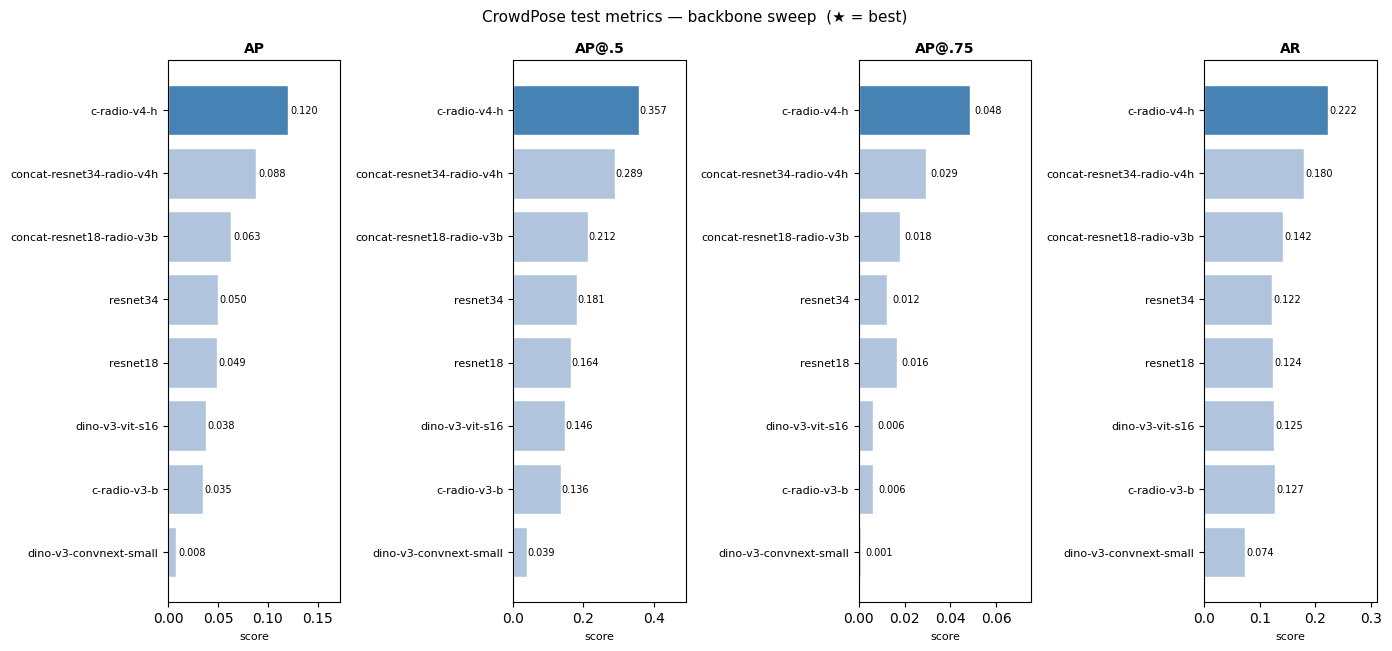

In [17]:

# ── Metrics bar chart ─────────────────────────────────────────────────────────
#
# Loads test_results.json for every task and plots the main CrowdPose metrics
# as grouped horizontal bars, sorted by AP.

PLOT_METRICS = {
    "AP":     "test/crowdpose/AP",
    "AP@.5":  "test/crowdpose/AP .5",
    "AP@.75": "test/crowdpose/AP .75",
    "AR":     "test/crowdpose/AR",
}

metric_rows = []
for tid in sorted(task_runs):
    name = backbone_names.get(tid, f"task_{tid}")
    results_path = task_runs[tid] / "test_results.json"
    if not results_path.exists():
        continue
    with open(results_path) as f:
        raw = json.load(f).get("metrics", {})
    row = {"backbone": name}
    for label, key in PLOT_METRICS.items():
        row[label] = raw.get(key, float("nan"))
    metric_rows.append(row)

metrics_df = pd.DataFrame(metric_rows).set_index("backbone").sort_values("AP", ascending=True)

fig, axes = plt.subplots(1, len(PLOT_METRICS), figsize=(14, max(3, len(metrics_df) * 0.7 + 1)))

for ax, col in zip(axes, PLOT_METRICS):
    vals = metrics_df[col]
    best = vals.max()
    colors = ["steelblue" if v == best else "lightsteelblue" for v in vals]
    bars = ax.barh(metrics_df.index, vals, color=colors, edgecolor="white")
    ax.set_title(col, fontsize=10, fontweight="bold")
    ax.set_xlabel("score", fontsize=8)
    ax.set_xlim(0, min(1.0, best * 1.35 + 0.01))
    ax.tick_params(axis="y", labelsize=8)
    for bar, val in zip(bars, vals):
        if not (val != val):  # skip NaN
            ax.text(
                bar.get_width() + 0.002, bar.get_y() + bar.get_height() / 2,
                f"{val:.3f}", va="center", ha="left", fontsize=7,
            )

fig.suptitle("CrowdPose test metrics — backbone sweep  (★ = best)", fontsize=11)
fig.tight_layout()
plt.show()


In [18]:
# ── Run inference ─────────────────────────────────────────────────────────────
#
# For each backbone, forward-pass all images as a single batch.
# Outputs are kept as numpy for visualisation.
#
# predictions[tid][img_idx] = dict with keys:
#   kpts_pixel  [N, K, 2]  — pixel coords on the padded MAX_SIZE × MAX_SIZE image
#   scores      [N]        — slot objectness scores
#   kpt_scores  [N, K]     — per-keypoint scores

predictions: dict[int, list[dict]] = {}

with torch.no_grad():
    for tid, module in sorted(modules.items()):
        batch = torch.stack(padded_images)  # [B, 3, 128, 128]
        pred = module._forward({"image": batch})

        kpts_canonical = pred["keypoints"].cpu()        # [B, N, K, 2]
        scores_all     = pred["scores"].cpu()           # [B, N]
        kpt_scores_all = pred["keypoint_scores"].cpu()  # [B, N, K]

        B = kpts_canonical.shape[0]
        img_wh = torch.tensor([[MAX_SIZE, MAX_SIZE]], dtype=torch.float32).expand(B, -1)
        kpts_pixel_all = canonical_to_pixel(kpts_canonical, img_wh)  # [B, N, K, 2]

        predictions[tid] = [
            {
                "kpts_pixel": kpts_pixel_all[i].numpy(),
                "scores":     scores_all[i].numpy(),
                "kpt_scores": kpt_scores_all[i].numpy(),
            }
            for i in range(B)
        ]

print(f"Inference done for {len(predictions)} backbone(s).")


Inference done for 8 backbone(s).


In [19]:
# ── Visualisation helper ──────────────────────────────────────────────────────

def plot_keypoints_with_slots(
    ax: plt.Axes,
    img_np: np.ndarray,
    kpts_pixel: np.ndarray,
    scores: np.ndarray,
    kpt_scores: np.ndarray,
    top_k: int = TOP_K_SLOTS,
    score_thresh: float = SCORE_THRESH,
    radius: float = 2.5,
) -> None:
    """Overlay predicted keypoints on *ax*.

    Args:
        ax:          matplotlib axes to draw on.
        img_np:      [H, W, 3] uint8 display image.
        kpts_pixel:  [N, K, 2] keypoints in pixel space (x, y).
        scores:      [N] slot objectness scores.
        kpt_scores:  [N, K] per-keypoint scores.
        top_k:       number of highest-scoring slots to display.
        score_thresh: minimum slot score; slots below this are skipped.
        radius:      circle radius in pixels.
    """
    ax.imshow(img_np, origin="upper")

    H, W = img_np.shape[:2]
    cmap  = plt.colormaps["tab10"]
    order = np.argsort(scores)[::-1][:top_k]

    # predict_visibility=False → kpt_scores all ≈ 0.5; skip per-keypoint filtering
    use_kpt_filter = kpt_scores.max() > 0.6

    for rank, slot_idx in enumerate(order):
        if scores[slot_idx] < score_thresh:
            continue
        slot_color = cmap(rank % 10)

        for k_idx in range(kpts_pixel.shape[1]):
            if use_kpt_filter and kpt_scores[slot_idx, k_idx] < 0.5:
                continue
            x, y = kpts_pixel[slot_idx, k_idx]
            if not (0 <= x < W and 0 <= y < H):
                continue
            circle = mpatches.Circle(
                (x, y), radius=radius,
                facecolor="white", edgecolor=slot_color,
                linewidth=1.0, alpha=0.9, zorder=2,
            )
            ax.add_patch(circle)
            ax.text(
                x, y, str(k_idx),
                ha="center", va="center",
                fontsize=3, color=slot_color, fontweight="bold", zorder=3,
            )

    ax.axis("off")


In [20]:
%matplotlib inline

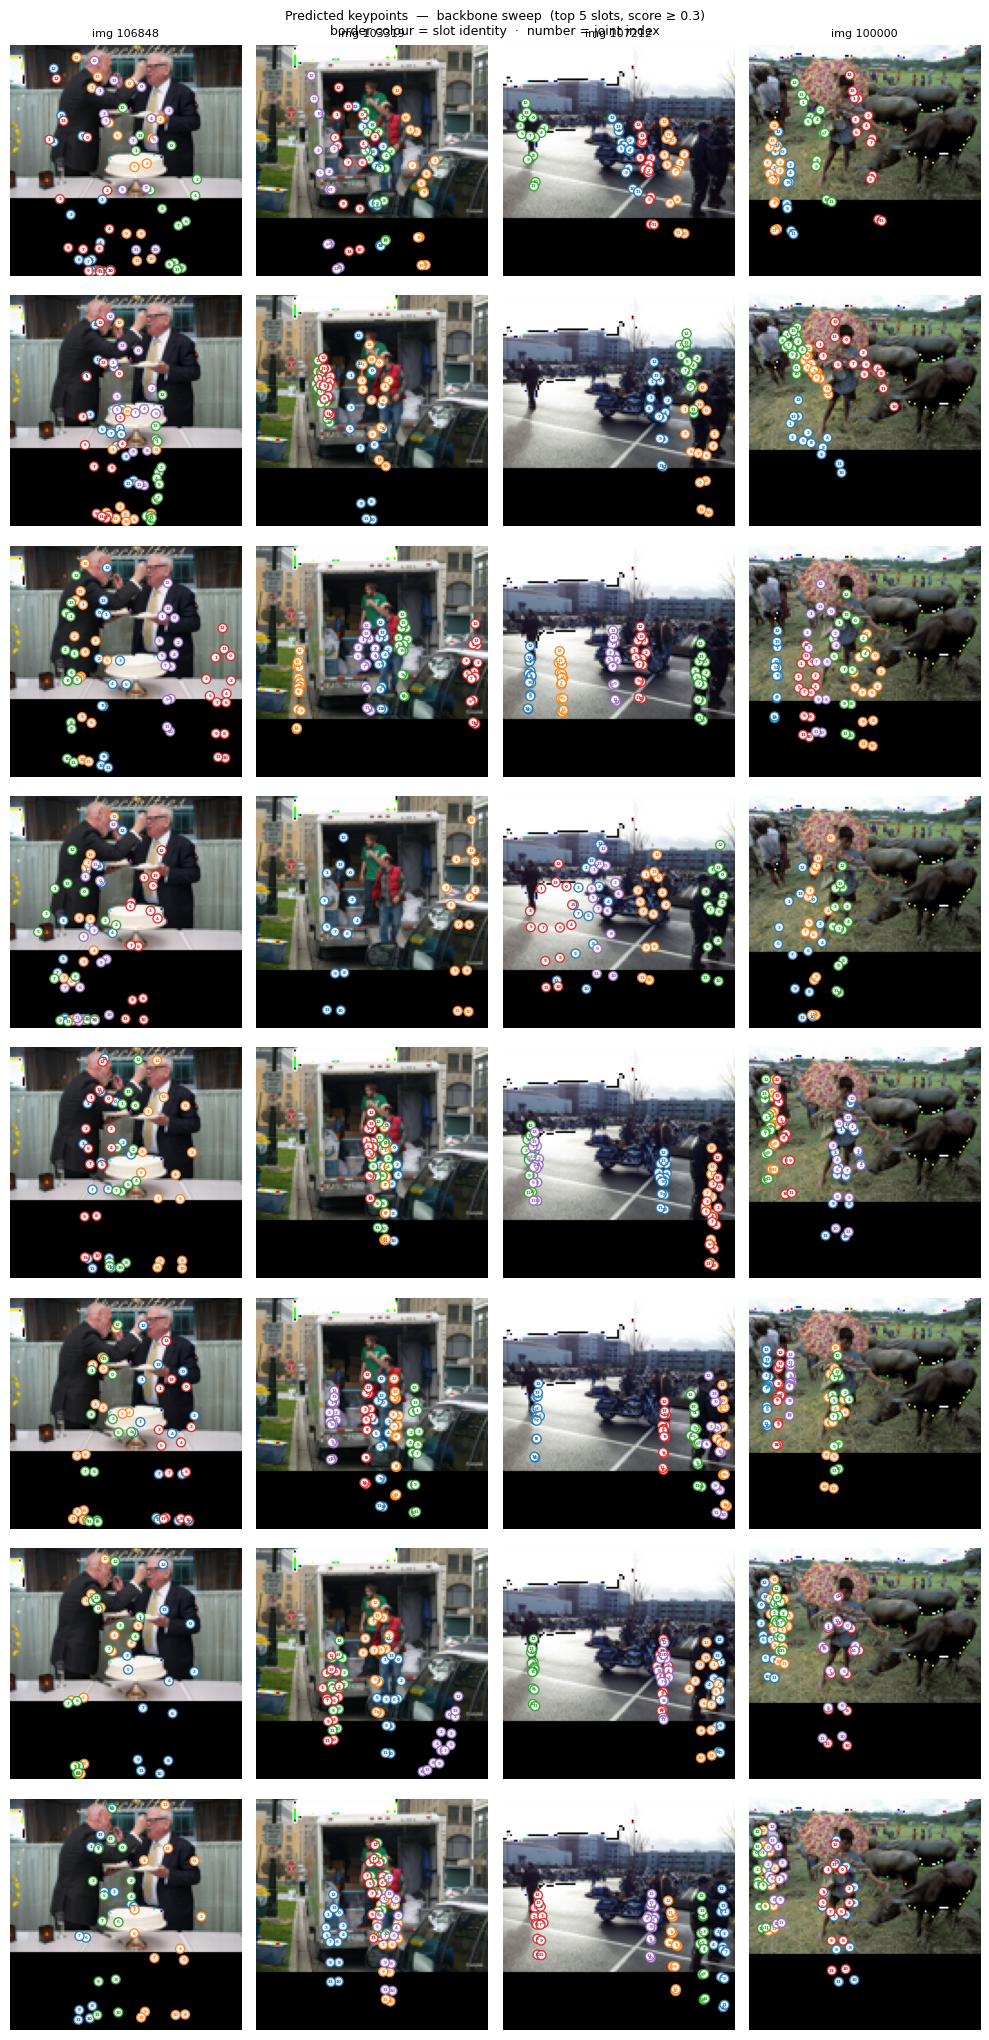

Joint index legend:
   0  left_shoulder
   1  right_shoulder
   2  left_elbow
   3  right_elbow
   4  left_wrist
   5  right_wrist
   6  left_hip
   7  right_hip
   8  left_knee
   9  right_knee
  10  left_ankle
  11  right_ankle
  12  head
  13  neck


In [21]:

# ── Display grid: backbones × images ─────────────────────────────────────────

loaded_tids = sorted(t for t in task_runs if t in modules)

n_rows = len(loaded_tids)
n_cols = len(EXAMPLE_IMAGE_IDS)
fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(n_cols * 2.5, n_rows * 2.6),
    squeeze=False,
)

for row, tid in enumerate(loaded_tids):
    backbone = backbone_names.get(tid, f"task_{tid}")

    for col in range(n_cols):
        ax   = axes[row, col]
        pred = predictions[tid][col]
        plot_keypoints_with_slots(
            ax,
            display_images[col],
            pred["kpts_pixel"],
            pred["scores"],
            pred["kpt_scores"],
        )
        if col == 0:
            ax.set_ylabel(
                backbone,
                fontsize=9, labelpad=6,
                rotation=0, ha="right", va="center",
            )
        if row == 0:
            ax.set_title(f"img {EXAMPLE_IMAGE_IDS[col]}", fontsize=8)

fig.suptitle(
    f"Predicted keypoints  —  backbone sweep  "
    f"(top {TOP_K_SLOTS} slots, score ≥ {SCORE_THRESH})\n"
    f"border colour = slot identity  ·  number = joint index",
    fontsize=9,
)
fig.tight_layout()
plt.show()

# Joint index legend
print("Joint index legend:")
for idx in range(14):
    print(f"  {idx:2d}  {JOINT_NAMES[idx]}")
